In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import scipy

datapath = "../week6/collected_data_spring_2.csv"

df = pd.read_csv(datapath)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

print(df.shape)

MAX_REPLICA_COUNT = df['Count'].max() + 1

replica_graphs = []

def get_replica_row(replica_num, group):
    if len(group) >= replica_num:
        return group.iloc[replica_num-1:replica_num]

grouped = df.groupby('Timestamp')

node_stats = grouped.apply(lambda x: x.iloc[0]).reset_index(drop=True)
pod_stats = grouped.apply(lambda x: x.iloc[1]).reset_index(drop=True)

node_stats['Memory'] = node_stats['Memory'].str.split("Mi").apply(lambda x: int(x[0]))

(55599, 6)


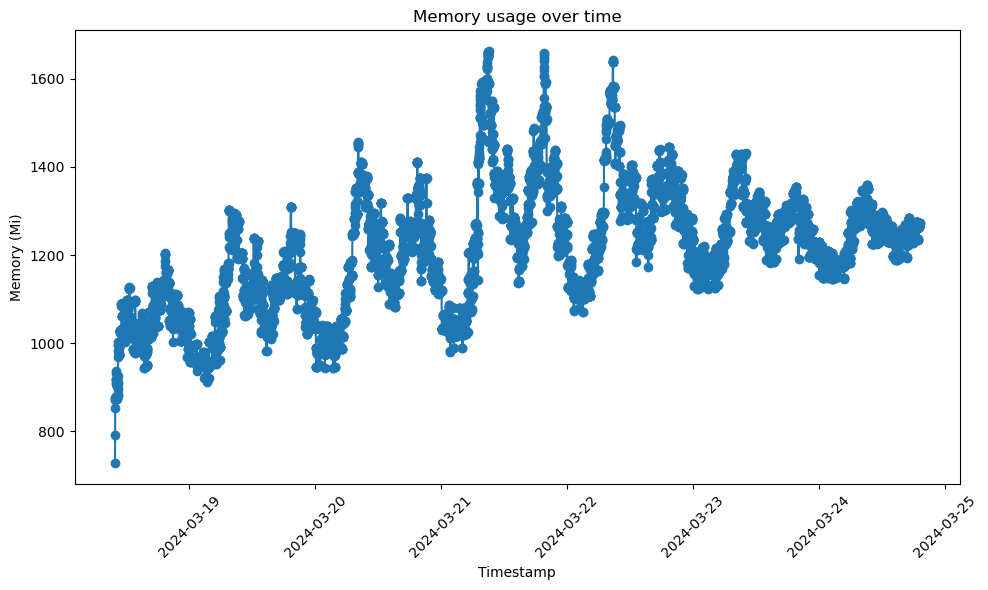

In [3]:
plt.figure(figsize=(10, 6))
plt.plot(node_stats.sort_values(by='Timestamp')['Timestamp'], node_stats['Memory'], marker='o', linestyle='-')
plt.title('Memory usage over time')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()

<AxesSubplot:xlabel='Lag', ylabel='Autocorrelation'>

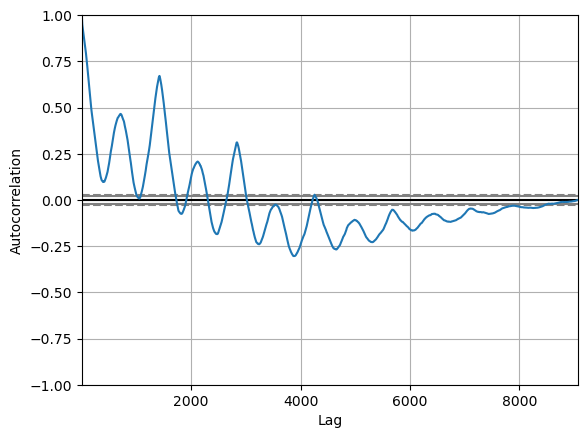

In [4]:
from pandas.plotting import autocorrelation_plot

autocorrelation_plot(node_stats['Memory'])


In [5]:
from statsmodels.tsa.arima.model import ARIMA

node_mem = node_stats[['Timestamp', 'Memory']]
node_mem = node_mem.set_index('Timestamp')
node_mem.index = node_mem.index.to_period('min')
node_mem

,Memory
Timestamp,
2024-03-18 09:48,728
2024-03-18 09:49,792
2024-03-18 09:50,854
2024-03-18 09:51,872
2024-03-18 09:52,875
...,...
2024-03-24 19:10,1273
2024-03-24 19:11,1272
2024-03-24 19:12,1271


In [6]:
arima_model = ARIMA(node_mem, order=(5,1,0))
arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                 Memory   No. Observations:                 9071
Model:                 ARIMA(5, 1, 0)   Log Likelihood              -38658.996
Date:                Tue, 30 Apr 2024   AIC                          77329.992
Time:                        14:34:12   BIC                          77372.668
Sample:                    03-18-2024   HQIC                         77344.508
                         - 03-24-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0110      0.010     -1.121      0.262      -0.030       0.008
ar.L2         -0.0119      0.010     -1.156      0.248      -0.032       0.008
ar.L3         -0.0288      0.011     -2.571      0.0

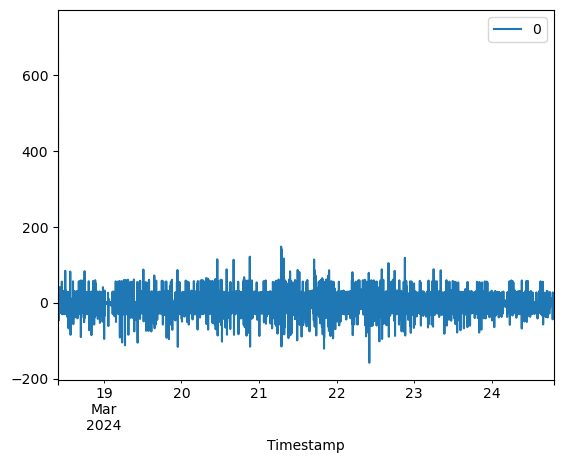

In [7]:
residuals = pd.DataFrame(arima_fit.resid)
residuals.plot()
plt.show()

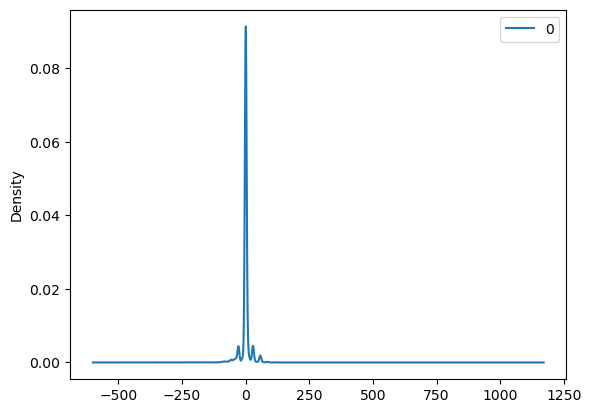

In [8]:
residuals.plot(kind='kde')
plt.show()

In [9]:
node_mem.describe()

,Memory
count,9071.000000
mean,1206.225223
std,136.287644
min,728.000000
25%,1110.000000
50%,1216.000000
75%,1291.000000
max,1663.000000


TOTAL ITER: 908


/var/folders/z9/y035yh4x00981tpfgng15kb00000gn/T/ipykernel_48843/1982149075.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('predicted=%f, expected=%f' % (output[0], obs))


predicted=1188.001367, expected=1187.000000
predicted=1250.850775, expected=1193.000000
predicted=1318.519426, expected=1318.000000
predicted=1319.957519, expected=1321.000000
predicted=1227.978986, expected=1229.000000
predicted=1262.551395, expected=1265.000000
predicted=1236.359011, expected=1236.000000
predicted=1252.651505, expected=1228.000000
predicted=1271.451969, expected=1267.000000
predicted=1263.972177, expected=1272.000000
Test RMSE: 11.840


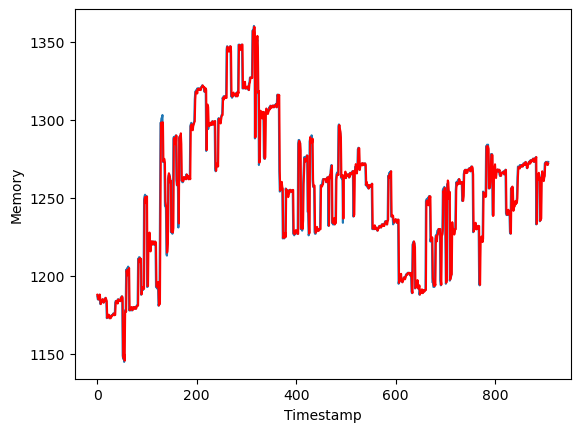

In [10]:
from sklearn.metrics import mean_squared_error

X_vals = node_mem.values
train_size = int(X_vals.shape[0] * 0.9)

X_train, X_test = X_vals[0:train_size], X_vals[train_size:X_vals.shape[0]]

history = [x for x in X_train]
predictions = list()

print("TOTAL ITER:", X_test.shape[0])

PRINT_EVERY = 100
for t in range(X_test.shape[0]):
    model = ARIMA(history, order=(5,1,0))
    model_fit = model.fit()
    output = model_fit.forecast()
    predictions.append(output[0])
    obs = X_test[t]
    history.append(obs)
    if t % PRINT_EVERY == 0:
        print('predicted=%f, expected=%f' % (output[0], obs))

rmse = np.sqrt(mean_squared_error(X_test, predictions))
print('Test RMSE: %.3f' % rmse)
plt.plot(X_test)
plt.plot(predictions, color='red')
plt.xlabel("Timestamp")
plt.ylabel("Memory")
plt.show()